#Data Preprocessing

Import PyTorch to the notebook

In [ ]:
import torch

Use GPU instead of CPU to maximize the training


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print ("Device:", device)

Device: cuda


Check what GPU are we using

In [ ]:
if torch.cuda.is_available():
  print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


Download dataset to the notebook

In [ ]:
from google.colab import drive
import subprocess
import os

drive.mount("/content/drive")

project_dir = Path("/content/drive/MyDrive/ColorizationAssignment")
project_dir.mkdir(parents=True, exist_ok=True)

drive_zip = project_dir / "fashionpedia_train.zip"
local_zip = Path("/content/fashionpedia_train.zip")

if drive_zip.exists():
    print("Copying saved dataset from Drive...")
    shutil.copy2(drive_zip, local_zip)
else:
    print("Downloading dataset for the first time...")
    subprocess.run(
        [
            "wget", "-c", "--show-progress",
            "-O", str(local_zip),
            "https://s3.amazonaws.com/ifashionist-dataset/images/train2020.zip",
        ],
        check=True,
    )

    # Copy completely before making it the saved ZIP.
    temporary_zip = project_dir / "fashionpedia_train.zip.partial"
    shutil.copy2(local_zip, temporary_zip)
    os.replace(temporary_zip, drive_zip)
    print("Dataset saved to Drive.")

print("Dataset ready:", local_zip)

--2026-09-25 07:46:35--  https://s3.amazonaws.com/ifashionist-dataset/images/train2020.zip
Resolving s3.amazonaws.com (s3.amazonaws.com)... 52.217.165.208, 16.15.229.40, 16.15.228.236, ...
Connecting to s3.amazonaws.com (s3.amazonaws.com)|52.217.165.208|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3344364592 (3.1G) [application/zip]
Saving to: ‘/content/fashionpedia_train.zip’

/content/fashionped 100%[===================>]   3.11G  15.4MB/s    in 3m 31s  

2026-09-25 07:50:07 (15.1 MB/s) - ‘/content/fashionpedia_train.zip’ saved [3344364592/3344364592]



In [ ]:
import random
import shutil
import zipfile
from pathlib import Path

zip_path = Path("/content/fashionpedia_train.zip")
image_dir = Path("/content/fashionpedia_sample")
image_dir.mkdir(parents=True, exist_ok=True)

random.seed(42)

with zipfile.ZipFile(zip_path) as archive:
    # Find image files regardless of their folder inside the ZIP.
    image_names = [
        name for name in archive.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
        and not name.startswith("__MACOSX/")
    ]

    print("Images found in ZIP:", len(image_names))

    # Choose the same random images whenever this cell is run again.
    chosen_names = random.sample(image_names, min(30_000, len(image_names)))

    image_paths = []

    for number, name in enumerate(chosen_names):
        extension = Path(name).suffix.lower()
        destination = image_dir / f"fashion_{number:05d}{extension}"

        # Copy only the selected images, instead of extracting the entire ZIP.
        if not destination.exists():
            with archive.open(name) as source, open(destination, "wb") as target:
                shutil.copyfileobj(source, target)

        image_paths.append(destination)

print("Selected images:", len(image_paths))

Images found in ZIP: 45623
Selected images: 30000


##Prepare RGB images as Lab training pairs

In [ ]:
import numpy as np
from PIL import Image
from skimage.color import rgb2lab
from torch.utils.data import Dataset

In [ ]:
class ColorizationDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, position):
        # Open a Fashionpedia photo from its file path.
        with Image.open(self.paths[position]) as image:
            image = image.convert("RGB")
            image = image.resize((128, 128), Image.Resampling.BICUBIC)

        # Convert RGB pixel values to 0–1, then to Lab.
        rgb = np.asarray(image, dtype=np.float32) / 255.0
        lab = rgb2lab(rgb).astype(np.float32)

        # One input channel (L); two target channels (a and b).
        L = lab[:, :, 0]
        ab = lab[:, :, 1:3]

        # Use the same scaling as your corrected VOC run.
        L = (L / 50.0) - 1.0
        ab = ab / 128.0

        L_tensor = torch.from_numpy(L).unsqueeze(0)
        ab_tensor = torch.from_numpy(ab.transpose(2, 0, 1))

        return L_tensor, ab_tensor

In [ ]:
# The selected image paths are already randomly ordered.
split = int(0.8 * len(image_paths))

train_paths = image_paths[:split]
val_paths = image_paths[split:]

train_dataset = ColorizationDataset(train_paths)
val_dataset = ColorizationDataset(val_paths)

sample_L, sample_ab = train_dataset[0]

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("L shape:", sample_L.shape)
print("ab shape:", sample_ab.shape)

Training images: 24000
Validation images: 6000
L shape: torch.Size([1, 128, 128])
ab shape: torch.Size([2, 128, 128])


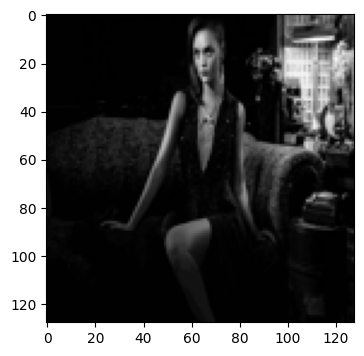

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize = (4,4))
plt.imshow(sample_L.squeeze(0).numpy(), cmap = "gray")
plt.show()

#Build U-Net

In [ ]:
import torch.nn as nn

# Two convolution layers used repeatedly throughout the U-Net.
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class ColorizationUNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder: learn features while reducing image size.
        self.enc1 = DoubleConv(1, 32)       # 128 × 128
        self.enc2 = DoubleConv(32, 64)      # 64 × 64
        self.enc3 = DoubleConv(64, 128)     # 32 × 32
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(128, 256)  # 16 × 16

        # Decoder: increase image size again.
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(256, 128)    # 128 from up3 + 128 from enc3

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(128, 64)     # 64 from up2 + 64 from enc2

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(64, 32)      # 32 from up1 + 32 from enc1

        # Produce two channels: predicted a and predicted b.
        self.output = nn.Conv2d(32, 2, kernel_size=1)

    def forward(self, x):
        # Save encoder outputs for the skip connections.
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        middle = self.bottleneck(self.pool(e3))

        # Combine decoder features with matching encoder features.
        d3 = self.up3(middle)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)

model = ColorizationUNet().to(device)

In [ ]:
# sample_L has shape (1, 128, 128).
# Add a batch dimension to make it (1, 1, 128, 128).
test_input = sample_L.unsqueeze(0).to(device)

# We are only checking shapes here, so no training is needed.
model.eval()
with torch.no_grad():
    test_output = model(test_input)

print("Input shape: ", test_input.shape)
print("Output shape:", test_output.shape)

Input shape:  torch.Size([1, 1, 128, 128])
Output shape: torch.Size([1, 2, 128, 128])


In [ ]:
from torch.utils.data import DataLoader

# Load 16 images at a time. Shuffle only the training images.
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Compare predicted a/b channels with the real a/b channels.
loss_function = nn.MSELoss()

# Adam updates the U-Net's weights to reduce that error.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# The assignment requires 15–20 epochs. We will use 20.
total_epochs = 20

print("Training batches per epoch:", len(train_loader))
print("Validation batches per epoch:", len(val_loader))

Training batches per epoch: 1500
Validation batches per epoch: 375


In [ ]:
L_batch, ab_batch = next(iter(train_loader))

print("Dataset sizes:", len(train_dataset), len(val_dataset))
print("Batch counts:", len(train_loader), len(val_loader))
print("Input and target:", L_batch.shape, ab_batch.shape)
print("L range:", L_batch.min().item(), L_batch.max().item())
print("ab range:", ab_batch.min().item(), ab_batch.max().item())

Dataset sizes: 24000 6000
Batch counts: 1500 375
Input and target: torch.Size([16, 1, 128, 128]) torch.Size([16, 2, 128, 128])
L range: -1.0 1.0
ab range: -0.5640909075737 0.6417815685272217


In [ ]:
def color_weighted_mse(predicted_ab, true_ab):
    chroma = torch.linalg.vector_norm(true_ab, dim=1, keepdim=True)
    weights = 1.0 + 2.0 * torch.clamp(chroma / 0.35, max=1.0)
    squared_error = (predicted_ab - true_ab).square()
    return (squared_error * weights).mean() / weights.mean()


# Use a separate folder for this 30,000-image, weighted-loss experiment.
checkpoint_dir = project_dir / "checkpoints_30k_weighted"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

model = ColorizationUNet().to(device)
loss_function = color_weighted_mse
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

total_epochs = 20
start_epoch = 0
train_losses = []
val_losses = []

# Find the most recent completely saved epoch.
checkpoints = sorted(checkpoint_dir.glob("checkpoint_epoch_*.pt"))

if checkpoints:
    latest = checkpoints[-1]
    saved = torch.load(latest, map_location=device, weights_only=True)

    if saved["dataset_size"] != len(image_paths):
        raise ValueError("Checkpoint and dataset sizes differ. Check the dataset settings.")

    model.load_state_dict(saved["model_state"])
    optimizer.load_state_dict(saved["optimizer_state"])
    start_epoch = saved["completed_epoch"]
    train_losses = saved["train_losses"]
    val_losses = saved["val_losses"]

    print(f"Restored {latest.name}. Next epoch: {start_epoch + 1}")
else:
    print("No checkpoint found. Starting at epoch 1.")

In [ ]:
import time

for epoch in range(start_epoch, total_epochs):
    epoch_start = time.time()

    # Training
    model.train()
    train_loss_sum = 0.0

    for L_batch, ab_batch in train_loader:
        # Move the grayscale inputs and colour targets to the GPU.
        L_batch = L_batch.to(device, non_blocking=True)
        ab_batch = ab_batch.to(device, non_blocking=True)

        optimizer.zero_grad()

        # Predict a and b from L, then calculate the MSE.
        predicted_ab = model(L_batch)
        loss = loss_function(predicted_ab, ab_batch)

        # Update the U-Net.
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * L_batch.size(0)

    average_train_loss = train_loss_sum / len(train_dataset)

    # Validation: measure error on images held aside
    model.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for L_batch, ab_batch in val_loader:
            L_batch = L_batch.to(device, non_blocking=True)
            ab_batch = ab_batch.to(device, non_blocking=True)

            predicted_ab = model(L_batch)
            loss = loss_function(predicted_ab, ab_batch)

            val_loss_sum += loss.item() * L_batch.size(0)

    average_val_loss = val_loss_sum / len(val_dataset)

    # Keep the numbers for a training graph later.
    train_losses.append(average_train_loss)
    val_losses.append(average_val_loss)

    minutes = (time.time() - epoch_start) / 60
    print(
        f"Epoch {epoch + 1:02d}/{total_epochs} | "
        f"Train MSE: {average_train_loss:.5f} | "
        f"Validation MSE: {average_val_loss:.5f} | "
        f"Time: {minutes:.1f} min"
    )

Epoch 01/20 | Train MSE: 0.01578 | Validation MSE: 0.01597 | Time: 6.5 min
Epoch 02/20 | Train MSE: 0.01487 | Validation MSE: 0.01438 | Time: 6.4 min
Epoch 03/20 | Train MSE: 0.01435 | Validation MSE: 0.01441 | Time: 6.5 min
Epoch 04/20 | Train MSE: 0.01393 | Validation MSE: 0.01396 | Time: 6.4 min
Epoch 05/20 | Train MSE: 0.01354 | Validation MSE: 0.01314 | Time: 6.4 min
Epoch 06/20 | Train MSE: 0.01326 | Validation MSE: 0.01310 | Time: 6.4 min
Epoch 07/20 | Train MSE: 0.01303 | Validation MSE: 0.01297 | Time: 6.2 min
Epoch 08/20 | Train MSE: 0.01282 | Validation MSE: 0.01294 | Time: 6.2 min
Epoch 09/20 | Train MSE: 0.01266 | Validation MSE: 0.01287 | Time: 6.2 min
Epoch 10/20 | Train MSE: 0.01260 | Validation MSE: 0.01312 | Time: 6.2 min
Epoch 11/20 | Train MSE: 0.01235 | Validation MSE: 0.01252 | Time: 6.3 min
Epoch 12/20 | Train MSE: 0.01221 | Validation MSE: 0.01248 | Time: 6.4 min
Epoch 13/20 | Train MSE: 0.01202 | Validation MSE: 0.01298 | Time: 6.4 min
Epoch 14/20 | Train MSE: 

##Plot the losses

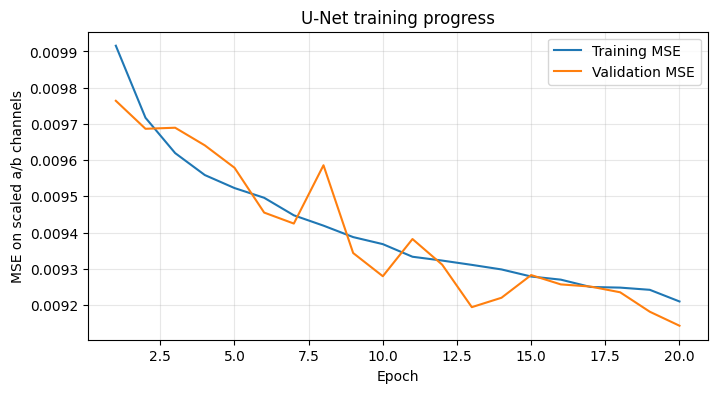

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_losses, label="Training MSE")
plt.plot(epochs, val_losses, label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE on scaled a/b channels")
plt.title("U-Net training progress")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##Compare predictions with real colour photos

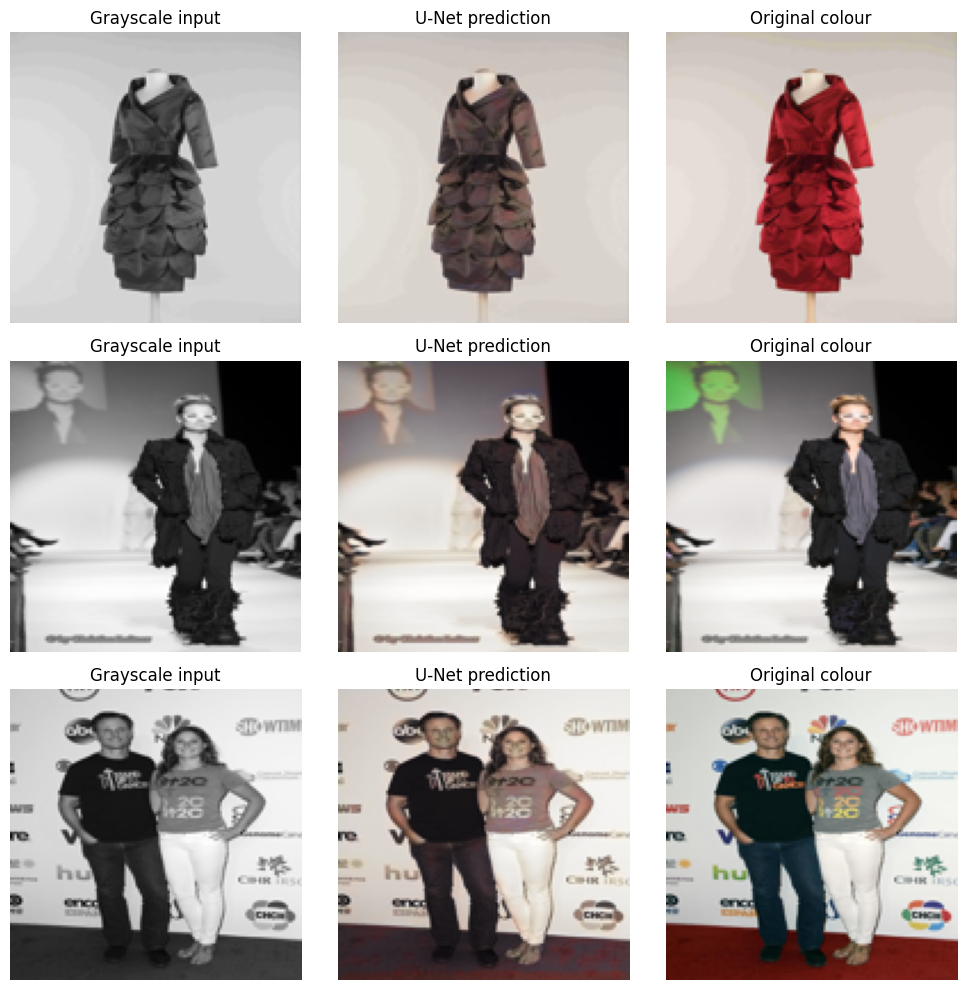

In [ ]:
import numpy as np
from skimage.color import lab2rgb

model.eval()

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for row, index in enumerate([0, 10, 20]):
    # Get an image that was held aside for validation.
    L_tensor, ab_tensor = val_dataset[index]

    # Add a batch dimension and predict its a/b channels.
    with torch.no_grad():
        predicted_ab = model(
            L_tensor.unsqueeze(0).to(device)
        )[0].cpu()

    # Undo the scaling used in ColorizationDataset.
    L = (L_tensor.squeeze(0).numpy() + 1.0) * 50.0
    real_ab = ab_tensor.numpy().transpose(1, 2, 0) * 128.0
    predicted_ab = predicted_ab.numpy().transpose(1, 2, 0) * 128.0

    # Build Lab images: neutral grayscale, predicted colour, real colour.
    zeros_ab = np.zeros_like(real_ab)
    grayscale = lab2rgb(np.dstack((L, zeros_ab)))
    prediction = lab2rgb(np.dstack((L, predicted_ab)))
    original = lab2rgb(np.dstack((L, real_ab)))

    for ax, image, title in zip(
        axes[row],
        [grayscale, prediction, original],
        ["Grayscale input", "U-Net prediction", "Original colour"]
    ):
        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

Saving images.jpg to images.jpg


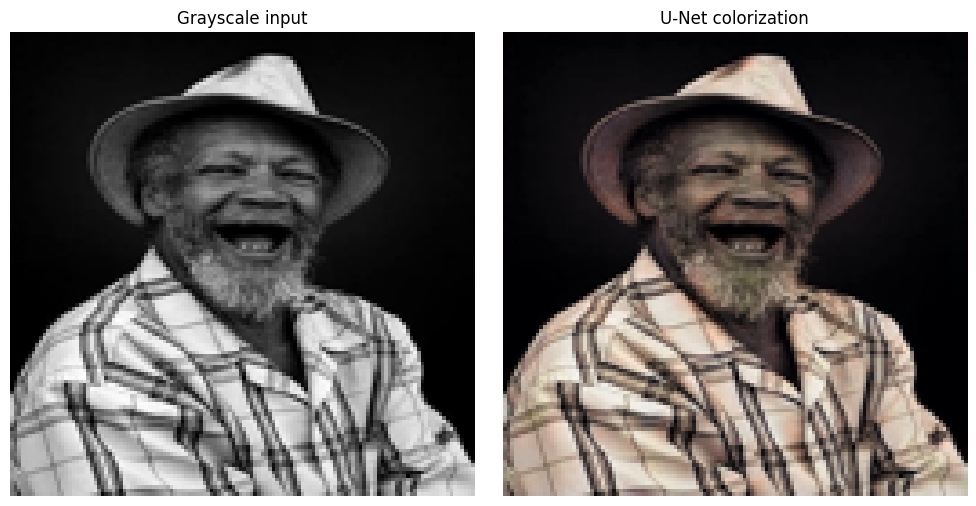

In [ ]:
from google.colab import files
import io

# 1. Upload one photograph.
uploaded = files.upload()
filename = next(iter(uploaded))

# 2. Make it grayscale and resize it exactly as the training images were.
photo = Image.open(io.BytesIO(uploaded[filename]))
gray_photo = photo.convert("L").resize((128, 128), Image.Resampling.BICUBIC)
gray_rgb = np.asarray(gray_photo.convert("RGB"), dtype=np.float32) / 255.0

# 3. Extract and normalize the L channel using your training settings.
L = rgb2lab(gray_rgb)[:, :, 0].astype(np.float32)
L_input = torch.from_numpy((L / 50.0) - 1.0)
L_input = L_input.unsqueeze(0).unsqueeze(0).to(device)

# 4. Ask your trained model to predict the a and b colour channels.
model.eval()
with torch.no_grad():
    predicted_ab = model(L_input)[0].cpu().numpy()

predicted_ab = predicted_ab.transpose(1, 2, 0) * 128.0

# 5. Combine the original L channel with the predicted a and b channels.
predicted_lab = np.dstack((L, predicted_ab))
colorized = np.clip(lab2rgb(predicted_lab), 0, 1)

# 6. Compare the input and result.
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(gray_photo, cmap="gray")
axes[0].set_title("Grayscale input")
axes[1].imshow(colorized)
axes[1].set_title("U-Net colorization")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()